# Cell motility

A motile cell crawls: it pulls itself over the substrate in some direction, keeps that direction for a
while, and then turns. Here this is a **persistent random walk of the whole cell**, the motility model of
PhysiCell (Ghaffarizadeh et al., *PLoS Comput. Biol.* 2018), with the same four parameters per cell:

| parameter | symbol | meaning |
|---|---|---|
| `migration_speed` | $v$ | speed of an isolated cell |
| `persistence_time` | $\tau$ | mean duration of a straight run |
| `migration_bias` | $b$ | 0: random directions, 1: always the bias direction |
| `migration_bias_direction` | $\mathbf e$ | unit vector the cell is drawn to, e.g. up a chemical gradient |

Every element $i$ of a motile cell $c$ gets one extra term in its equation of motion,

$$\dot{\mathbf x}_i = \frac{\mathbf F_i}{\eta} + v_c\,\mathbf d_c$$

with $\mathbf d_c$ the current unit direction of the cell (`motility_direction`). The term is the same for
all elements of the cell, so on its own it moves the cell without deforming it. It is equivalent to a
traction force $\eta\,v\,\mathbf d$ on every element. With the scaling $\eta = \eta_0/N$ of the element
drag, the total traction $\eta_0\,v\,\mathbf d$ of the cell does not depend on the number of elements $N$.

In every step of length $\Delta t$ a cell turns with probability $\Delta t/\tau$. The new direction is

$$\mathbf d = \frac{(1-b)\,\boldsymbol\xi + b\,\mathbf e}{\left|(1-b)\,\boldsymbol\xi + b\,\mathbf e\right|}$$

with $\boldsymbol\xi$ a random unit vector, uniform on the circle (2D) or the sphere (3D).

All data here comes from the C++ solver through the `motility` example ($v = 1$, $\Delta t = 0.01$,
$\mathbf e$ along $x$):

```bash
E=build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.motility
D=mechanics/micromechanics/docs/notebooks/data
for tau in 0.25 1 4; do
  $E msd 2 $tau > $D/motility_msd_2d_tau$tau.csv
  $E tracks 2 $tau > $D/motility_tracks_2d_tau$tau.csv
done
for dims in 1 3; do $E msd $dims 1 > $D/motility_msd_${dims}d_tau1.csv; done
for bias in 0.25 0.5 0.75 1; do $E msd 2 1 $bias > $D/motility_msd_2d_tau1_bias$bias.csv; done
$E tracks 2 1 0.5 > $D/motility_tracks_2d_tau1_bias0.5.csv
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load(name):
    file = Path("data") / name
    header = file.read_text().splitlines()[0].lstrip("# ").split()
    params = dict(item.split("=") for item in header)
    params = {key: (value if key == "experiment" else float(value)) for key, value in params.items()}
    return params, np.genfromtxt(file, delimiter=",", names=True, skip_header=1)


def persistent_walk(time, speed, persistence_time):
    # mean squared displacement of a persistent random walk (Fuerth's formula)
    return 2 * speed**2 * persistence_time * (time - persistence_time * (1 - np.exp(-time / persistence_time)))

## What the persistence time does

Eight cells of 13 elements each, without bias, followed for 20 time units. Every track is drawn from the
cell's own starting point. All cells move at the same speed $v = 1$, so every track has the same length of
20; only how often they turn differs.

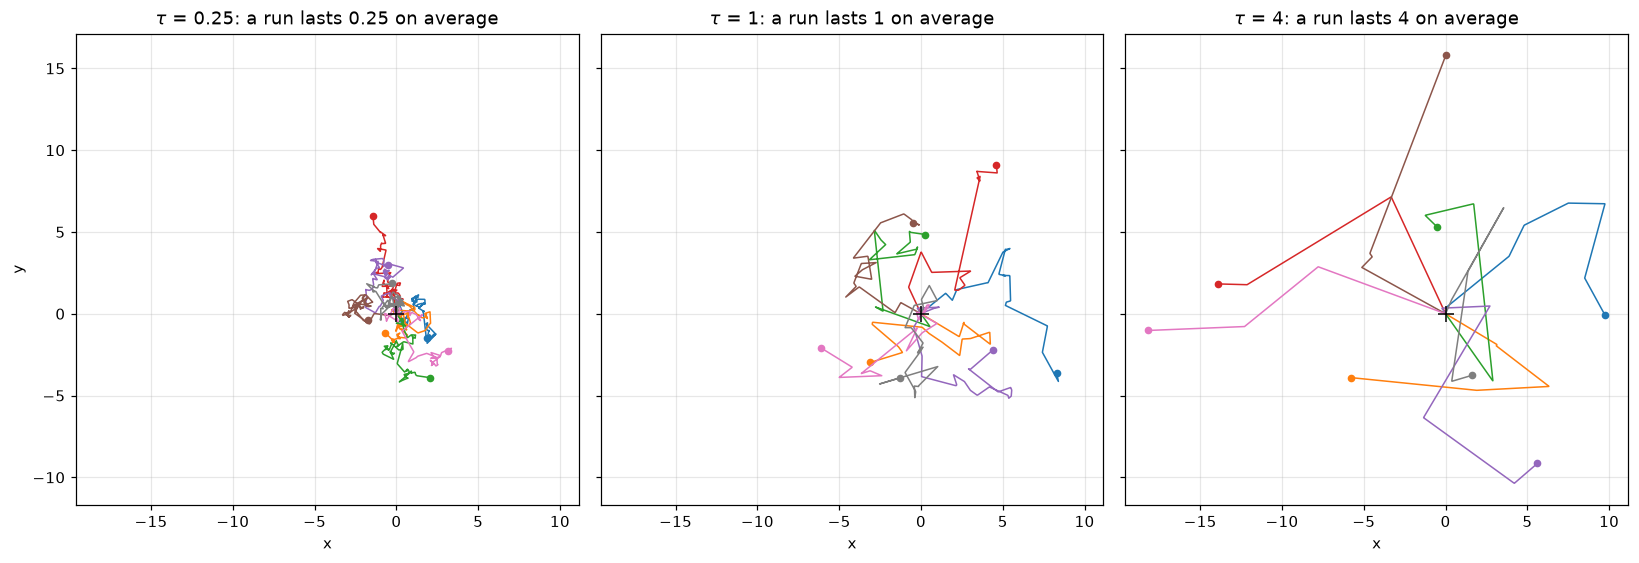

In [2]:
taus = ["0.25", "1", "4"]
fig, axes = plt.subplots(1, len(taus), figsize=(15, 5), sharex=True, sharey=True)

for ax, tau in zip(axes, taus):
    params, table = load(f"motility_tracks_2d_tau{tau}.csv")
    for cell in np.unique(table["cell"]):
        track = table[table["cell"] == cell]
        ax.plot(track["x"], track["y"], linewidth=1)
        ax.plot(track["x"][-1], track["y"][-1], "o", markersize=4, color=ax.lines[-1].get_color())

        # the cell crawls at the migration speed: the length of its track is speed * time
        length = np.hypot(np.diff(track["x"]), np.diff(track["y"])).sum()
        assert length <= params["migration_speed"] * track["time"][-1] * (1 + 1e-6)
    ax.plot(0, 0, "k+", markersize=10)
    ax.set(aspect="equal", xlabel="x", title=rf"$\tau$ = {tau}: a run lasts {tau} on average")
axes[0].set(ylabel="y")
fig.tight_layout()

## Mean squared displacement

For an unbiased walk the mean squared displacement is known in closed form (Fürth's formula):

$$\langle |\Delta\mathbf x|^2\rangle = 2\,v^2\tau\left[t - \tau\left(1 - e^{-t/\tau}\right)\right]$$

- At **short times** ($t \ll \tau$) the cell has not turned yet and moves in a straight line:
  $\langle |\Delta\mathbf x|^2\rangle \approx v^2 t^2$.
- At **long times** ($t \gg \tau$) the turns add up to diffusion: $\langle |\Delta\mathbf x|^2\rangle \approx 2 v^2\tau\,t$,
  which is an effective diffusion coefficient $D_\mathrm{eff} = v^2\tau/d$ in $d$ dimensions.

The formula contains no free parameter. Below it is compared with 2000 cells for three persistence times.

tau = 0.25: largest deviation from the formula 5.9%
tau =    1: largest deviation from the formula 2.0%
tau =    4: largest deviation from the formula 1.2%


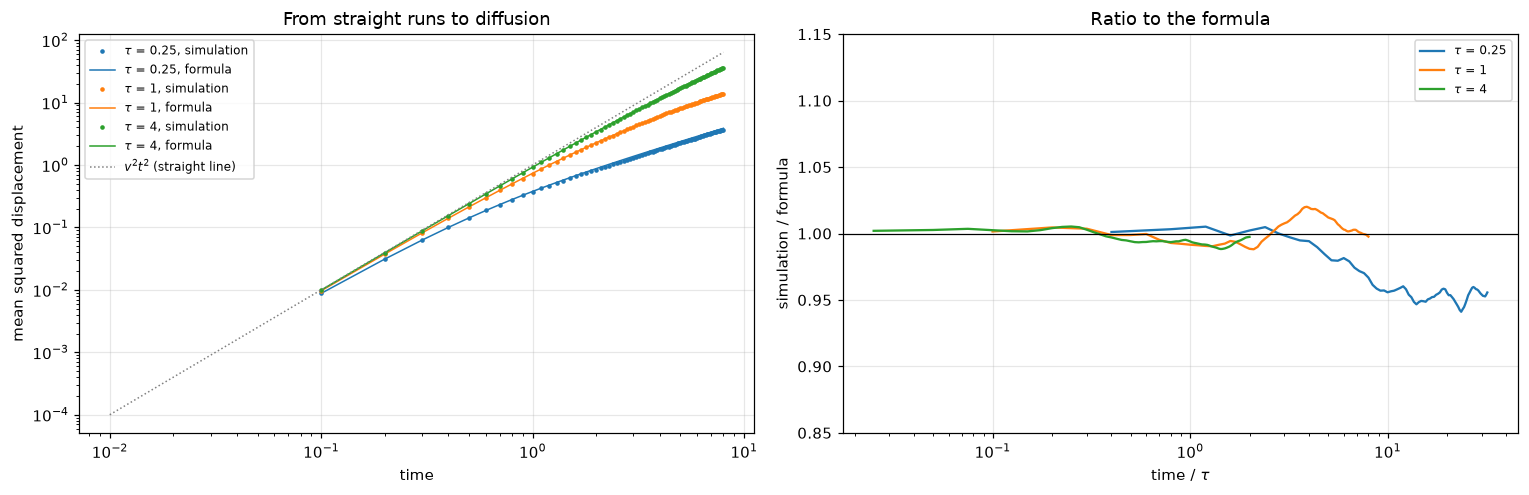

In [3]:
fig, (ax_log, ax_ratio) = plt.subplots(1, 2, figsize=(14, 4.6))

for tau in taus:
    params, table = load(f"motility_msd_2d_tau{tau}.csv")
    time, measured = table["time"][1:], table["mean_squared_displacement"][1:]
    expected = persistent_walk(time, params["migration_speed"], params["persistence_time"])

    line, = ax_log.loglog(time, measured, ".", markersize=4, label=rf"$\tau$ = {tau}, simulation")
    ax_log.loglog(time, expected, color=line.get_color(), linewidth=1, label=rf"$\tau$ = {tau}, formula")
    ax_ratio.semilogx(time / params["persistence_time"], measured / expected, color=line.get_color(), label=rf"$\tau$ = {tau}")

    # 2000 cells: the estimate is good to a few percent
    worst = np.abs(measured / expected - 1).max()
    assert worst < 0.1, f"tau = {tau}: off by {100 * worst:.1f}%"
    print(f"tau = {tau:>4}: largest deviation from the formula {100 * worst:.1f}%")

time = np.array([0.01, 8.0])
ax_log.loglog(time, time**2, color="gray", linestyle=":", linewidth=1, label="$v^2 t^2$ (straight line)")
ax_log.set(xlabel="time", ylabel="mean squared displacement", title="From straight runs to diffusion")
ax_log.legend(fontsize=8)

ax_ratio.axhline(1, color="black", linewidth=0.8)
ax_ratio.set(xlabel=r"time / $\tau$", ylabel="simulation / formula", ylim=(0.85, 1.15), title="Ratio to the formula")
ax_ratio.legend(fontsize=8)
fig.tight_layout()

### The same in one, two and three dimensions

The formula does not contain the number of dimensions: a cell covers the same distance whether it walks on
a line, on a plane or in space. Only the random direction is drawn differently.

1D: largest deviation from the formula 4.9%
2D: largest deviation from the formula 2.0%
3D: largest deviation from the formula 1.7%


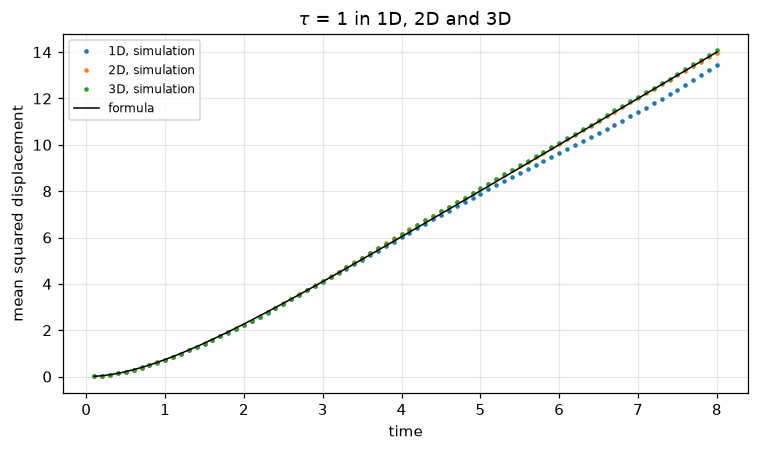

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.2))

for dims in (1, 2, 3):
    params, table = load(f"motility_msd_{dims}d_tau1.csv")
    time, measured = table["time"][1:], table["mean_squared_displacement"][1:]
    expected = persistent_walk(time, params["migration_speed"], params["persistence_time"])
    ax.plot(time, measured, ".", markersize=4, label=f"{dims}D, simulation")

    worst = np.abs(measured / expected - 1).max()
    assert worst < 0.1, f"{dims}D: off by {100 * worst:.1f}%"
    print(f"{dims}D: largest deviation from the formula {100 * worst:.1f}%")

ax.plot(time, expected, color="black", linewidth=1, label="formula")
ax.set(xlabel="time", ylabel="mean squared displacement", title=r"$\tau$ = 1 in 1D, 2D and 3D")
ax.legend(fontsize=8)
fig.tight_layout()

## Bias: following a direction

With a bias $b > 0$ every new direction leans towards $\mathbf e$. Averaged over the random part, a new
direction points along $\mathbf e$ by

$$m(b) = \left\langle \mathbf d\cdot\mathbf e \right\rangle = \frac{1}{2\pi}\int_0^{2\pi}
\frac{(1-b)\cos\theta + b}{\sqrt{(1-b)^2 + b^2 + 2b(1-b)\cos\theta}}\;d\theta \qquad \text{(2D)}$$

so the cells drift along $\mathbf e$ with the speed $v\,m(b)$. The relation is not linear: a bias of 0.5 is
not "half the speed".

b =    0: drift speed -0.006, expected -0.000
b = 0.25: drift speed +0.164, expected 0.169
b =  0.5: drift speed +0.634, expected 0.637
b = 0.75: drift speed +0.971, expected 0.972
b =    1: drift speed +1.000, expected 1.000


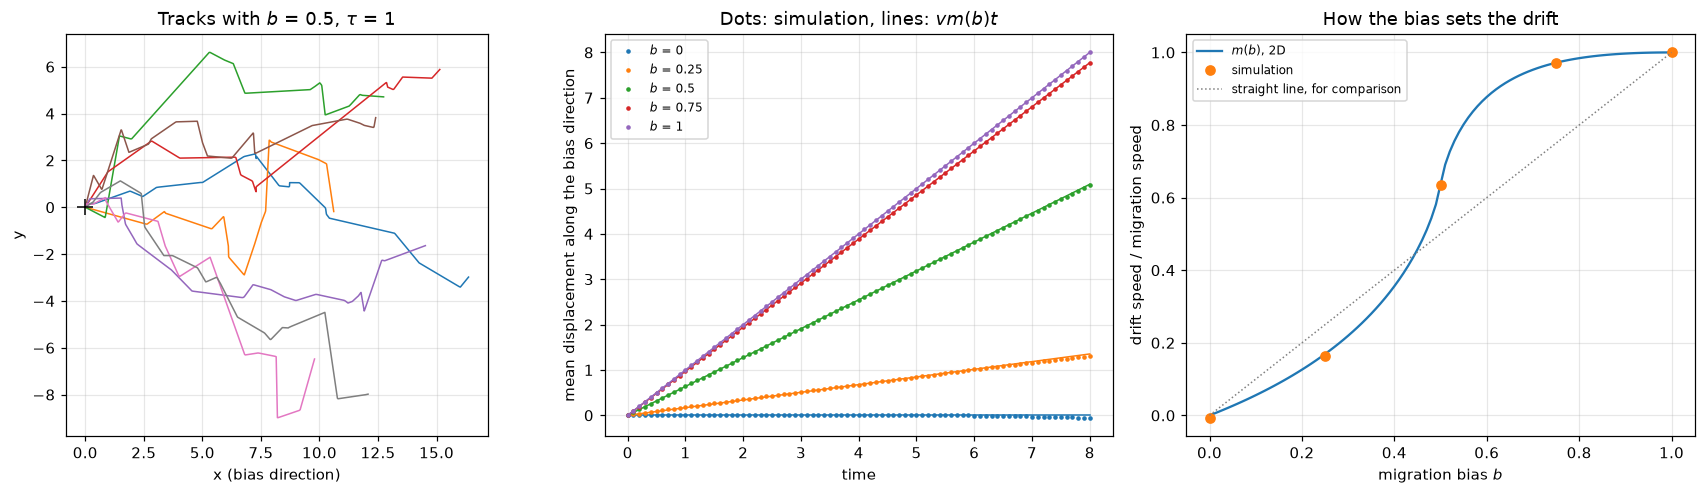

In [5]:
def mean_alignment(bias, samples=200001):
    # mean of d . e over the random direction, in two dimensions
    theta = np.linspace(0, 2 * np.pi, samples)
    x = (1 - bias) * np.cos(theta) + bias
    y = (1 - bias) * np.sin(theta)
    length = np.hypot(x, y)
    alignment = np.divide(x, length, out=np.zeros_like(x), where=length > 1e-12)
    return np.trapezoid(alignment, theta) / (2 * np.pi)


fig, (ax_tracks, ax_drift, ax_speed) = plt.subplots(1, 3, figsize=(16, 4.6))

params, table = load("motility_tracks_2d_tau1_bias0.5.csv")
for cell in np.unique(table["cell"]):
    track = table[table["cell"] == cell]
    ax_tracks.plot(track["x"], track["y"], linewidth=1)
ax_tracks.plot(0, 0, "k+", markersize=10)
ax_tracks.set(aspect="equal", xlabel="x (bias direction)", ylabel="y", title=r"Tracks with $b$ = 0.5, $\tau$ = 1")

biases = ["0", "0.25", "0.5", "0.75", "1"]
measured_speeds = []
for bias in biases:
    params, table = load("motility_msd_2d_tau1.csv" if bias == "0" else f"motility_msd_2d_tau1_bias{bias}.csv")
    line, = ax_drift.plot(table["time"], table["mean_displacement_along_bias"], ".", markersize=4, label=f"$b$ = {bias}")
    expected_speed = params["migration_speed"] * mean_alignment(float(bias))
    ax_drift.plot(table["time"], expected_speed * table["time"], color=line.get_color(), linewidth=1)

    measured_speed = np.polyfit(table["time"], table["mean_displacement_along_bias"], 1)[0]
    measured_speeds.append(measured_speed)
    # the mean of 2000 cells; without bias it scatters around zero
    assert abs(measured_speed - expected_speed) < 0.05, f"b = {bias}: drift speed {measured_speed}"
    print(f"b = {bias:>4}: drift speed {measured_speed:+.3f}, expected {expected_speed:.3f}")

ax_drift.set(xlabel="time", ylabel="mean displacement along the bias direction", title="Dots: simulation, lines: $v m(b) t$")
ax_drift.legend(fontsize=8)

b = np.linspace(0, 1, 101)
ax_speed.plot(b, [mean_alignment(value) for value in b], label="$m(b)$, 2D")
ax_speed.plot([float(bias) for bias in biases], measured_speeds, "o", label="simulation")
ax_speed.plot(b, b, color="gray", linestyle=":", linewidth=1, label="straight line, for comparison")
ax_speed.set(xlabel="migration bias $b$", ylabel="drift speed / migration speed", title="How the bias sets the drift")
ax_speed.legend(fontsize=8)
fig.tight_layout()

## Reading the result

- **The walk is the textbook persistent random walk.** The mean squared displacement follows Fürth's formula
  from a tenth of a time unit to eight, for all three persistence times and in one, two and three dimensions, with
  no fitted parameter.
- **Choosing $v$ and $\tau$:** $v$ is what a tracking experiment measures over short intervals; $\tau$ sets
  where the mean squared displacement bends from $t^2$ to $t$. Over long times only the combination
  $D_\mathrm{eff} = v^2\tau/d$ matters.
- **Choosing $b$:** the drift speed along the bias direction is $v\,m(b)$, not $v\,b$. In 2D a bias of 0.5
  already gives 64% of the full speed, and above 0.5 a cell never moves against the bias direction.
- **The cell keeps its shape.** All elements get the same drift, so an isolated cell is moved, not deformed
  (tested to $10^{-10}$ in the unit tests).

### Caveats

- **Time is discrete.** Turns happen only at steps, so runs last a whole number of steps with mean exactly
  $\tau$. Compared with the continuous formula, the long-time spreading is lower by the factor
  $1 - \Delta t/2\tau$: 2% for the shortest $\tau$ here. Keep $\Delta t \ll \tau$.
- **This is not the motility mechanism of the sub-cellular element literature**, where elements are added at
  the leading edge and removed at the rear, which changes the shape of the cell (SEM2, Chattaraj et al. 2023).
  Here the cell is pushed as a whole.
- **No contact inhibition.** A cell keeps pushing when it meets another cell and stalls only through their
  repulsion. In the unit tests two cells driven head-on come to rest against each other.
- **Turns are instantaneous** and the speed is constant: there is no pause, no acceleration and no memory of
  the previous direction.
- **Motility and thermal noise are independent.** Both can be on at once; they use separate random numbers.